# CP3 / S5 — Învățare: model v1 (CNN 1D) vs. baseline-uri, pe seed-uri, cu intervale de încredere

**Întrebarea (neschimbată din CP2):** pentru fiecare bătaie ECG (MLII, fereastră de 200 de eșantioane) prezic clasa AAMI N / S / V / F; clasa Q este exclusă. Decizia clinică derivată: triaj bătaie anormală (S, V, F) vs. normală (N).

**Metoda de CI aleasă (planul spune: tabular / secvențial / spațial):**
* *tabular* — Random Forest și HistGradientBoosting pe trăsăturile R1 din CP2 (baseline-uri);
* *secvențial* — **CNN 1D pe fereastra filtrată a bătăii** (+ intervalele RR ca intrare auxiliară) = **model v1**;
* *spațial* — nu se aplică (o singură derivație, fără dimensiune spațială).

**Protocol (identic cu CP2):** DS1 = train (23 înreg.), DS2 = test (21 înreg.), fără niciun pacient comun. Hiperparametrii și pragurile se aleg doar în DS1 (CV grupat pe pacient); testul se atinge o singură dată per model și seed.

**Variabilitate și intervale:** 5 seed-uri (± = deviația standard pe seed-uri) + interval de încredere 95% prin bootstrap **pe pacienți** (se reeșantionează cele 21 de înregistrări de test), cu aceleași reeșantionări pentru toate metodele, deci comparațiile sunt **perechi**.

**Rezultatul negativ se raportează ca atare:** la sfârșit, celula `verdict` spune automat dacă diferența v1 − baseline are IC care exclude 0.

In [1]:
!pip -q install wfdb

from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, time, shutil, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from collections import Counter
from scipy.signal import butter, sosfiltfilt
from scipy.stats import skew, kurtosis
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore", category=FutureWarning)

ZIP_PATH = "/content/drive/MyDrive/mit-bih-arrhythmia-database-1.0.0.zip"
EXTRACT_ROOT = "/content/mit_bih_extracted"


def find_data_dir(search_root):
    required = [f"{rec}.{ext}" for rec in ["100", "101"] for ext in ["hea", "dat", "atr"]]
    for root, dirs, files in os.walk(search_root):
        if all(f in files for f in required):
            return root
    return None


os.makedirs(EXTRACT_ROOT, exist_ok=True)
DATA_DIR = find_data_dir(EXTRACT_ROOT)
if DATA_DIR is None:
    if not os.path.isfile(ZIP_PATH):
        raise FileNotFoundError(f"Arhiva nu exista: {ZIP_PATH}")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        bad = zf.testzip()
        if bad is not None:
            raise RuntimeError(f"Arhiva este corupta: {bad}")
        zf.extractall(EXTRACT_ROOT)
    DATA_DIR = find_data_dir(EXTRACT_ROOT)
if DATA_DIR is None:
    raise FileNotFoundError("Nu s-a gasit directorul cu fisierele MIT-BIH.")
print("Director date:", DATA_DIR)

Mounted at /content/drive
Director date: /content/mit_bih_extracted/mit-bih-arrhythmia-database-1.0.0


In [2]:
# ---------------- CONFIG (tot ce se poate modifica e aici) ----------------
FS = 360
WIN_BEFORE, WIN_AFTER = 90, 110      # 200 esantioane, R la indexul 90 (identic cu CP1)
R_IDX = WIN_BEFORE
N_LOCAL = 10                          # media locala a ultimelor 10 intervale RR (cauzala)
BAND = (0.5, 40.0)                    # filtru trece-banda Butterworth ord. 2, zero-phase (sosfiltfilt)
EXCLUDE_Q = True                      # decizia pentru clasa Q (8 train / 7 test)
CLASSES = ['N', 'S', 'V', 'F'] + ([] if EXCLUDE_Q else ['Q'])
PCA_VAR = 0.95                        # R2: cate componente explica 95% din varianta (fit doar pe train)
N_TREES = 100
N_SEEDS = 5                           # seed-uri pentru RF pe test
CV_FOLDS = 5                          # CV grupat pe pacient, doar in DS1
N_BOOT = 1000                         # bootstrap pe pacienti (inregistrari) pe test
OUT_DIR = "/content/cp2_outputs"

DS1_TRAIN = [
    '101', '106', '108', '109', '112', '114', '115', '116',
    '118', '119', '122', '124', '201', '202', '203', '205',
    '207', '208', '209', '215', '220', '223', '230'
]
DS2_TEST = [
    '100', '103', '105', '111', '113', '117', '121', '123',
    '200', '210', '212', '213', '214', '219', '221', '222',
    '228', '231', '232', '233', '234'
]
PATIENT_OF = {'202': '201'}           # 201 si 202 = acelasi pacient -> acelasi grup

AAMI_MAP = {
    'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
    'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
    'V': 'V', 'E': 'V',
    'F': 'F',
    '/': 'Q', 'f': 'Q', 'Q': 'Q'
}
COL = {'N': 'tab:green', 'S': 'tab:orange', 'V': 'tab:red', 'F': 'tab:purple', 'Q': 'tab:gray'}

assert set(DS1_TRAIN).isdisjoint(DS2_TEST)
assert len(DS1_TRAIN) == 23 and len(DS2_TEST) == 21
assert PATIENT_OF['202'] == '201' and '201' in DS1_TRAIN and '202' in DS1_TRAIN
os.makedirs(OUT_DIR, exist_ok=True)

In [3]:
# ---------------- CONFIG CP3 ----------------
import torch, torch.nn as nn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_curve

COD = "S5"
warnings.filterwarnings("ignore", category=RuntimeWarning)   # nanmean pe coloane nedefinite (ex. regula RR nu are macro-F1)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| torch", torch.__version__)

SEEDS = list(range(5))               # seed-uri pentru modelele cu aleator (RF, CNN)
EPOCHS, BATCH, LR_MAX = 12, 256, 3e-3
WEIGHT_DECAY, DROPOUT = 1e-4, 0.3
DO_MINI_TUNING = (DEVICE == "cuda")  # tuning minim pe CV grupat (DS1); pe CPU e prea lent -> implicit oprit
SP_TARGET = 0.97                     # specificitate tinta pentru pragul de triaj (ales pe DS1 out-of-fold)
N_BOOT, MAX_BINS = 1000, 400
OUT3 = "/content/cp3_outputs"
CACHE_DIR = "/content/drive/MyDrive/IC3_CP3_cache"
if not os.path.isdir("/content/drive/MyDrive"):
    CACHE_DIR = "/content/cp3_cache"
os.makedirs(OUT3, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
print("Cache:", CACHE_DIR)

Device: cuda | torch 2.14.1+cu130
Cache: /content/drive/MyDrive/IC3_CP3_cache


In [4]:
SOS = butter(2, BAND, btype='band', fs=FS, output='sos')


def extract_record(record_path, rec_id):
    """Aceeasi selectie de batai ca in CP1; in plus: filtrare, id inregistrare, medie RR locala."""
    record = wfdb.rdrecord(record_path)
    ann = wfdb.rdann(record_path, 'atr')

    names = [n.strip().upper() for n in record.sig_name]
    if 'MLII' not in names:
        raise ValueError(f"MLII lipseste din {record_path}: {record.sig_name}")
    sig = record.p_signal[:, names.index('MLII')].astype(np.float64)

    if not np.isclose(record.fs, FS):
        raise ValueError(f"Frecventa neasteptata {record.fs} Hz in {record_path}")
    if not np.isfinite(sig).all():
        raise ValueError(f"NaN/Inf in {record_path}")

    # filtrare pe intreaga inregistrare (inainte de taiere), ca sa nu apara efecte de margine in fiecare fereastra
    sig_f = sosfiltfilt(SOS, sig)

    valid = np.array([i for i, s in enumerate(ann.symbol) if s in AAMI_MAP])
    samples = ann.sample[valid].astype(np.int64)
    symbols = np.array([ann.symbol[i] for i in valid])
    rr_all = np.diff(samples) / FS                     # rr_all[k] = (samples[k+1]-samples[k])/fs

    pos = np.arange(1, len(valid) - 1)
    r = samples[pos]
    ok = (r - WIN_BEFORE >= 0) & (r + WIN_AFTER <= len(sig))
    pos, r = pos[ok], r[ok]

    idx = r[:, None] + np.arange(-WIN_BEFORE, WIN_AFTER)[None, :]
    rr_pre = rr_all[pos - 1]
    rr_post = rr_all[pos]
    rr_loc = np.array([rr_all[max(0, p - N_LOCAL):p].mean() for p in pos])   # doar trecutul (cauzal)
    y = np.array([AAMI_MAP[s] for s in symbols[pos]])

    return dict(
        raw=sig[idx].astype(np.float32),
        filt=sig_f[idx].astype(np.float32),
        y=y,
        rr_pre=rr_pre.astype(np.float32),
        rr_post=rr_post.astype(np.float32),
        rr_loc=rr_loc.astype(np.float32),
        rec=np.full(len(pos), rec_id),
        r_sample=r,
    )


def load_split(data_dir, record_list, split_name):
    parts = []
    for k, rec_id in enumerate(record_list, start=1):
        print(f"{split_name}: {k}/{len(record_list)} - {rec_id}", flush=True)
        parts.append(extract_record(os.path.join(data_dir, rec_id), rec_id))
    D = {key: np.concatenate([p[key] for p in parts]) for key in parts[0]}
    D['patient'] = np.array([PATIENT_OF.get(r, r) for r in D['rec']])
    return D

In [5]:
t0 = time.time()
D_train = load_split(DATA_DIR, DS1_TRAIN, "TRAIN")
D_test = load_split(DATA_DIR, DS2_TEST, "TEST")
print(f"Ingestie: {time.time() - t0:.0f} s")

# Verificare fata de CP1: trebuie sa obtin EXACT aceleasi numere
EXP_TR = {'N': 47883, 'S': 998, 'V': 3807, 'F': 415, 'Q': 8}
EXP_TE = {'N': 42159, 'S': 1781, 'V': 3200, 'F': 387, 'Q': 7}
assert len(D_train['y']) == 53111 and dict(Counter(D_train['y'])) == EXP_TR, "Train difera de CP1"
assert len(D_test['y']) == 47534 and dict(Counter(D_test['y'])) == EXP_TE, "Test difera de CP1"
assert set(D_train['patient']).isdisjoint(set(D_test['patient'])), "Leakage de pacient!"
for D in (D_train, D_test):
    assert np.isfinite(D['filt']).all() and np.isfinite(D['rr_loc']).all()
print("OK: aceleasi numere ca la CP1, zero pacienti comuni intre train si test.")

TRAIN: 1/23 - 101
TRAIN: 2/23 - 106
TRAIN: 3/23 - 108
TRAIN: 4/23 - 109
TRAIN: 5/23 - 112
TRAIN: 6/23 - 114
TRAIN: 7/23 - 115
TRAIN: 8/23 - 116
TRAIN: 9/23 - 118
TRAIN: 10/23 - 119
TRAIN: 11/23 - 122
TRAIN: 12/23 - 124
TRAIN: 13/23 - 201
TRAIN: 14/23 - 202
TRAIN: 15/23 - 203
TRAIN: 16/23 - 205
TRAIN: 17/23 - 207
TRAIN: 18/23 - 208
TRAIN: 19/23 - 209
TRAIN: 20/23 - 215
TRAIN: 21/23 - 220
TRAIN: 22/23 - 223
TRAIN: 23/23 - 230
TEST: 1/21 - 100
TEST: 2/21 - 103
TEST: 3/21 - 105
TEST: 4/21 - 111
TEST: 5/21 - 113
TEST: 6/21 - 117
TEST: 7/21 - 121
TEST: 8/21 - 123
TEST: 9/21 - 200
TEST: 10/21 - 210
TEST: 11/21 - 212
TEST: 12/21 - 213
TEST: 13/21 - 214
TEST: 14/21 - 219
TEST: 15/21 - 221
TEST: 16/21 - 222
TEST: 17/21 - 228
TEST: 18/21 - 231
TEST: 19/21 - 232
TEST: 20/21 - 233
TEST: 21/21 - 234
Ingestie: 4 s
OK: aceleasi numere ca la CP1, zero pacienti comuni intre train si test.


In [6]:
RR_NAMES = ['rr_pre', 'rr_post', 'rr_pre/rr_post', 'rr_pre/loc', 'rr_post/loc', 'rr_loc']


def rr_features(D):
    pre, post, loc = D['rr_pre'], D['rr_post'], D['rr_loc']
    return np.column_stack([pre, post, pre / post, pre / loc, post / loc, loc])


def morph_features(D):
    W = D['filt'].astype(np.float64)
    n = len(W)
    ar = np.arange(n)
    f = {}
    # varful R (cautam extremul in +-10 esantioane in jurul adnotarii)
    j = np.abs(W[:, R_IDX - 10:R_IDX + 11]).argmax(1) + R_IDX - 10
    f['r_amp'] = W[ar, j]
    f['r_off'] = j - R_IDX
    f['w_max'], f['w_min'] = W.max(1), W.min(1)
    f['w_ptp'] = f['w_max'] - f['w_min']
    f['w_argmax'], f['w_argmin'] = W.argmax(1) - R_IDX, W.argmin(1) - R_IDX
    qrs = W[:, R_IDX - 15:R_IDX + 26]
    f['qrs_area'] = np.abs(qrs).sum(1) / FS
    f['qrs_energy'] = (qrs ** 2).sum(1) / FS
    half = 0.5 * np.abs(qrs).max(1, keepdims=True)
    f['qrs_width'] = (np.abs(W[:, R_IDX - 30:R_IDX + 41]) > half).sum(1)
    d = np.diff(W[:, R_IDX - 20:R_IDX + 31], axis=1)
    f['slope_up'], f['slope_down'] = d.max(1), d.min(1)
    t = W[:, R_IDX + 40:]
    f['t_max'], f['t_min'] = t.max(1), t.min(1)
    f['t_amp'] = np.where(np.abs(f['t_max']) >= np.abs(f['t_min']), f['t_max'], f['t_min'])
    p = W[:, :R_IDX - 20]
    f['p_max'], f['p_min'] = p.max(1), p.min(1)
    f['w_mean'], f['w_std'] = W.mean(1), W.std(1)
    f['w_skew'], f['w_kurt'] = skew(W, axis=1), kurtosis(W, axis=1)
    f['qrs_over_t'] = np.abs(f['r_amp']) / (np.abs(f['t_amp']) + 1e-3)
    names = list(f.keys())
    return np.nan_to_num(np.column_stack([f[k] for k in names])), names


FEATURE_SETS = {
    'RR-only':       ('rr',),
    'Morph-only':    ('morph',),
    'R1 (RR+morf.)': ('rr', 'morph'),
    'R2 (PCA)':      ('pca',),
    'R2+RR':         ('pca', 'rr'),
}


def build_features(spec, fit, app):
    """fit = datele pe care se potriveste PCA (doar train/fold-train); app = datele de transformat."""
    Pf, Pa, names = [], [], []
    for kind in spec:
        if kind == 'rr':
            Pf.append(rr_features(fit)); Pa.append(rr_features(app)); names += RR_NAMES
        elif kind == 'morph':
            ff, nm = morph_features(fit); fa, _ = morph_features(app)
            Pf.append(ff); Pa.append(fa); names += nm
        elif kind == 'pca':
            pca = PCA(n_components=PCA_VAR, svd_solver='full', random_state=0).fit(fit['filt'])
            Pf.append(pca.transform(fit['filt'])); Pa.append(pca.transform(app['filt']))
            names += [f'pc{i + 1}' for i in range(pca.n_components_)]
    return np.hstack(Pf), np.hstack(Pa), names

In [7]:
CIDX = {c: i for i, c in enumerate(CLASSES)}
K = len(CLASSES)
MODEL_KEYS = ['filt', 'y', 'rr_pre', 'rr_post', 'rr_loc', 'rec', 'patient']


def subset(D, mask):
    return {k: D[k][mask] for k in MODEL_KEYS}


def to_int(y):
    return np.array([CIDX[c] for c in y])


def f1_from_cm(cm):
    tp = np.diag(cm).astype(float)
    fn = cm.sum(1) - tp
    fp = cm.sum(0) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0)
    sup = cm.sum(1)
    rec = tp / np.maximum(sup, 1)
    prec = tp / np.maximum(tp + fp, 1)
    return f1, rec, prec, sup


def macro_f1(cm):
    f1, _, _, sup = f1_from_cm(cm)
    return float(f1[sup > 0].mean())


def triage(y_true, pred):
    at, ap = (y_true != 'N'), (pred != 'N')
    se = (at & ap).sum() / max(at.sum(), 1)
    sp = (~at & ~ap).sum() / max((~at).sum(), 1)
    return float(se), float(sp)


def make_rf(seed):
    return RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=2,
                                  class_weight='balanced_subsample', n_jobs=-1, random_state=seed)


keep_tr = (D_train['y'] != 'Q') if EXCLUDE_Q else np.ones(len(D_train['y']), bool)
keep_te = (D_test['y'] != 'Q') if EXCLUDE_Q else np.ones(len(D_test['y']), bool)
Dtr, Dte = subset(D_train, keep_tr), subset(D_test, keep_te)
print(f"Train: {len(Dtr['y'])} bătăi, {len(np.unique(Dtr['patient']))} pacienți | "
      f"Test: {len(Dte['y'])} bătăi, {len(np.unique(Dte['patient']))} pacienți (Q exclus: {EXCLUDE_Q})")

sgkf = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=0)
folds = list(sgkf.split(np.zeros(len(Dtr['y'])), Dtr['y'], Dtr['patient']))
fold_tab = pd.DataFrame(
    [{**{'fold': k, 'pacienți val.': len(np.unique(Dtr['patient'][va]))},
      **{c: int((Dtr['y'][va] == c).sum()) for c in CLASSES}} for k, (tr, va) in enumerate(folds)]
)
for k, (tr, va) in enumerate(folds):
    assert set(Dtr['patient'][tr]).isdisjoint(set(Dtr['patient'][va])), "Leakage de pacient in CV!"
print("\nFold-uri CV (grupate pe pacient) — distribuția claselor în validare:")
print(fold_tab.to_string(index=False))

Train: 53103 bătăi, 22 pacienți | Test: 47527 bătăi, 21 pacienți (Q exclus: True)

Fold-uri CV (grupate pe pacient) — distribuția claselor în validare:
 fold  pacienți val.     N   S    V   F
    0              4  8641  87  961  19
    1              5 10990 388 1102 372
    2              4  6642   7  981   2
    3              5 12125 419  654   9
    4              4  9485  97  109  13


In [8]:
# Aceleasi fold-uri ca in CP2 (distributia N in validare din tabelul rulat la CP2)
assert fold_tab['N'].tolist() == [8641, 10990, 6642, 12125, 9485], "Fold-urile difera de CP2!"
assert len(Dtr['y']) == 53103 and len(Dte['y']) == 47527
print("OK: aceleasi fold-uri si aceleasi numere de bataie ca la CP2 (53.103 train / 47.527 test, fara Q).")

OK: aceleasi fold-uri si aceleasi numere de bataie ca la CP2 (53.103 train / 47.527 test, fara Q).


## Funcții comune: cache, metode, metrici
Fiecare predicție (OOF pe DS1 și test, pe seed) se salvează în Drive (`IC3_CP3_cache`). Dacă Colab se deconectează, relansezi celulele și continuă de unde a rămas. **Dacă schimbi codul unei metode, șterge folderul de cache.**

In [9]:
def tag():
    return f"e{EPOCHS}_lr{LR_MAX}_s{len(SEEDS)}"


def cached(fname, fn):
    path = os.path.join(CACHE_DIR, f"{tag()}_{fname}.npy")
    if os.path.isfile(path):
        print(f"   (din cache) {fname}", flush=True)
        return np.load(path)
    arr = fn()
    np.save(path, arr)
    return arr


def reorder_proba(clf, P):
    """sklearn ordoneaza clasele alfabetic -> le punem in ordinea CLASSES (N, S, V, F)."""
    out = np.zeros((P.shape[0], K))
    for j, c in enumerate(clf.classes_):
        out[:, CIDX[c]] = P[:, j]
    return out


def oof_predict(fp, seed):
    """Predictii out-of-fold pe DS1, cu fold-urile grupate pe pacient (aceleasi ca in CP2)."""
    oof = np.zeros((len(Dtr['y']), K))
    for k, (tr, va) in enumerate(folds):
        print(f"   fold {k + 1}/{len(folds)}", flush=True)
        oof[va] = fp(subset(Dtr, tr), subset(Dtr, va), seed)
    return oof


METHODS = {}


def run_method(key, label, role, fp, seeds):
    t0 = time.time()
    print(f"[{label}]", flush=True)
    oof = cached(f"oof_{key}", lambda: oof_predict(fp, 0))
    test = []
    for s in seeds:
        print(f"   test, seed {s}", flush=True)
        test.append(cached(f"test_{key}_s{s}", lambda s=s: fp(Dtr, Dte, s)))
    METHODS[key] = dict(label=label, role=role, kind='proba', oof=oof, test=test)
    print(f"   gata in {time.time() - t0:.0f} s")


def make_fp_rf(spec):
    def fp(fit, app, seed):
        Ftr, Fap, _ = build_features(spec, fit, app)
        clf = make_rf(seed).fit(Ftr, fit['y'])
        return reorder_proba(clf, clf.predict_proba(Fap))
    return fp


def fp_hgb(fit, app, seed):
    Ftr, Fap, _ = build_features(('rr', 'morph'), fit, app)
    clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=31,
                                         class_weight='balanced', early_stopping=False,
                                         random_state=seed).fit(Ftr, fit['y'])
    return reorder_proba(clf, clf.predict_proba(Fap))


def pooled_macro(oof):
    cm = confusion_matrix(Dtr['y'], np.array(CLASSES)[oof.argmax(1)], labels=CLASSES)
    return macro_f1(cm)


print("Functii definite.")

Functii definite.


## Model v1: CNN 1D (secvențial)
* Intrare: fereastra de 200 de eșantioane **filtrată** (aceeași ca la R1/R2 în CP2), standardizată cu media/abaterea globală din train (se păstrează amplitudinea relativă a bătăii, nu se normalizează pe bătaie).
* 3 blocuri Conv1D–BatchNorm–ReLU–MaxPool (16/32/64 canale), apoi straturi dense; **intervalele RR (6 valori, log, standardizate) intră printr-o ramură auxiliară** și se concatenează înainte de clasificator.
* Pierdere: entropie încrucișată **ponderată pe clase** (pondere = √(n_max/n_clasă)). Optimizator AdamW, schedule OneCycle, fără early stopping pe test.
* Ablație: același CNN **fără** intrarea RR, ca să se vadă dacă informația din formă aduce ceva peste RR (în CP2, RR dominau importanța).
* Pragul de triaj se alege pe predicțiile out-of-fold din DS1 (nu pe test).

In [10]:
class BeatNet(nn.Module):
    def __init__(self, n_rr=0, n_classes=4, ch=(16, 32, 64), drop=DROPOUT):
        super().__init__()
        c1, c2, c3 = ch
        self.conv = nn.Sequential(
            nn.Conv1d(1, c1, 7, padding=3), nn.BatchNorm1d(c1), nn.ReLU(), nn.MaxPool1d(2),    # 200 -> 100
            nn.Conv1d(c1, c2, 5, padding=2), nn.BatchNorm1d(c2), nn.ReLU(), nn.MaxPool1d(2),   # 100 -> 50
            nn.Conv1d(c2, c3, 5, padding=2), nn.BatchNorm1d(c3), nn.ReLU(), nn.MaxPool1d(2),   # 50 -> 25
        )
        self.n_rr = n_rr
        d = c3 * 25
        if n_rr > 0:
            self.rr = nn.Sequential(nn.Linear(n_rr, 16), nn.ReLU())
            d += 16
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(d, 64), nn.ReLU(),
                                  nn.Dropout(drop), nn.Linear(64, n_classes))

    def forward(self, x, r=None):
        h = self.conv(x).flatten(1)
        if self.n_rr > 0:
            h = torch.cat([h, self.rr(r)], dim=1)
        return self.head(h)


def _rr_input(D):
    return np.log(np.clip(rr_features(D), 1e-3, None)).astype(np.float32)


def fp_cnn(use_rr):
    def fp(fit, app, seed):
        t0 = time.time()
        torch.manual_seed(seed)
        np.random.seed(seed)
        mu, sd = float(fit['filt'].mean()), float(fit['filt'].std())
        Xf = torch.tensor(((fit['filt'] - mu) / sd)[:, None, :], dtype=torch.float32, device=DEVICE)
        Xa = torch.tensor(((app['filt'] - mu) / sd)[:, None, :], dtype=torch.float32, device=DEVICE)
        Rf = Ra = None
        if use_rr:
            rf_np, ra_np = _rr_input(fit), _rr_input(app)
            rmu, rsd = rf_np.mean(0), rf_np.std(0) + 1e-6
            Rf = torch.tensor((rf_np - rmu) / rsd, dtype=torch.float32, device=DEVICE)
            Ra = torch.tensor((ra_np - rmu) / rsd, dtype=torch.float32, device=DEVICE)
        y_np = to_int(fit['y'])
        yf = torch.tensor(y_np, dtype=torch.long, device=DEVICE)
        counts = np.bincount(y_np, minlength=K).astype(float)
        w = torch.tensor(np.sqrt(counts.max() / np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)

        model = BeatNet(n_rr=(Rf.shape[1] if use_rr else 0), n_classes=K).to(DEVICE)
        n = len(y_np)
        steps = int(np.ceil(n / BATCH))
        opt = torch.optim.AdamW(model.parameters(), lr=LR_MAX, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR_MAX, total_steps=EPOCHS * steps)
        lossf = nn.CrossEntropyLoss(weight=w)
        for ep in range(EPOCHS):
            model.train()
            perm = torch.randperm(n, device=DEVICE)
            tot = torch.zeros((), device=DEVICE)
            for i in range(steps):
                idx = perm[i * BATCH:(i + 1) * BATCH]
                out = model(Xf[idx], Rf[idx] if use_rr else None)
                loss = lossf(out, yf[idx])
                opt.zero_grad()
                loss.backward()
                opt.step()
                sched.step()
                tot += loss.detach() * len(idx)
            if ep == 0 or ep == EPOCHS - 1:
                print(f"      seed {seed} epoca {ep + 1}/{EPOCHS} loss={float(tot) / n:.4f} ({time.time() - t0:.0f} s)", flush=True)
        model.eval()
        outs = []
        with torch.no_grad():
            for i in range(0, len(Xa), 4096):
                o = model(Xa[i:i + 4096], Ra[i:i + 4096] if use_rr else None)
                outs.append(torch.softmax(o, dim=1).cpu().numpy())
        return np.concatenate(outs).astype(np.float64)
    return fp


# verificare rapida de forma (nu antreneaza): 1 pas pe date mici
_m = BeatNet(n_rr=6).to(DEVICE)
_o = _m(torch.zeros(4, 1, 200, device=DEVICE), torch.zeros(4, 6, device=DEVICE))
assert _o.shape == (4, K), _o.shape
print("BeatNet OK, parametri:", sum(p.numel() for p in _m.parameters()))

BeatNet OK, parametri: 117108


## Tuning minim (doar pe CV grupat în DS1; pe GPU)
Compar 3 configurații pentru CNN + RR după macro-F1 out-of-fold (seed 0). Testul nu e folosit. Dacă `DO_MINI_TUNING` e False (CPU), rămâne configurația implicită (12 epoci, lr 3e-3).

In [25]:
TUNE_GRID = [dict(EPOCHS=12, LR_MAX=3e-3), dict(EPOCHS=20, LR_MAX=3e-3), dict(EPOCHS=12, LR_MAX=1e-3)]
if DO_MINI_TUNING:
    res = []
    for g in TUNE_GRID:
        EPOCHS, LR_MAX = g['EPOCHS'], g['LR_MAX']
        print("Configuratie:", g, flush=True)
        oof = cached("oof_cnn_rr", lambda: oof_predict(fp_cnn(True), 0))
        res.append((pooled_macro(oof), g))
        print(f"   macro-F1 OOF (DS1) = {res[-1][0]:.3f}")
    best_cfg = max(res, key=lambda t: t[0])[1]
    EPOCHS, LR_MAX = best_cfg['EPOCHS'], best_cfg['LR_MAX']
    print("\nConfiguratie aleasa (CV grupat, DS1):", best_cfg)
else:
    print("Tuning oprit; configuratie fixa:", dict(EPOCHS=EPOCHS, LR_MAX=LR_MAX))

Configuratie: {'EPOCHS': 12, 'LR_MAX': 0.003}
   (din cache) oof_cnn_rr
   macro-F1 OOF (DS1) = 0.461
Configuratie: {'EPOCHS': 20, 'LR_MAX': 0.003}
   (din cache) oof_cnn_rr
   macro-F1 OOF (DS1) = 0.440
Configuratie: {'EPOCHS': 12, 'LR_MAX': 0.001}
   fold 1/5
      seed 0 epoca 1/12 loss=0.7307 (3 s)
      seed 0 epoca 12/12 loss=0.0329 (23 s)
   fold 2/5
      seed 0 epoca 1/12 loss=0.7307 (3 s)
      seed 0 epoca 12/12 loss=0.0487 (21 s)
   fold 3/5
      seed 0 epoca 1/12 loss=0.7627 (3 s)
      seed 0 epoca 12/12 loss=0.0434 (24 s)
   fold 4/5
      seed 0 epoca 1/12 loss=0.7093 (3 s)
      seed 0 epoca 12/12 loss=0.0326 (22 s)
   fold 5/5
      seed 0 epoca 1/12 loss=0.7485 (3 s)
      seed 0 epoca 12/12 loss=0.0462 (24 s)
   macro-F1 OOF (DS1) = 0.463

Configuratie aleasa (CV grupat, DS1): {'EPOCHS': 12, 'LR_MAX': 0.001}


## Rularea metodelor (fiecare celulă salvează în cache)

In [26]:
run_method('rf_r1', 'RF + R1 (baseline principal)', 'baseline',
           make_fp_rf(('rr', 'morph')), SEEDS)
run_method('rf_r2rr', 'RF + R2+RR', 'baseline',
           make_fp_rf(('pca', 'rr')), SEEDS)
for k in ('rf_r1', 'rf_r2rr'):
    print(f"{METHODS[k]['label']:<32} macro-F1 OOF (DS1) = {pooled_macro(METHODS[k]['oof']):.3f}")

[RF + R1 (baseline principal)]
   fold 1/5
   fold 2/5
   fold 3/5
   fold 4/5
   fold 5/5
   test, seed 0
   test, seed 1
   test, seed 2
   test, seed 3
   test, seed 4
   gata in 260 s
[RF + R2+RR]
   fold 1/5
   fold 2/5
   fold 3/5
   fold 4/5
   fold 5/5
   test, seed 0
   test, seed 1
   test, seed 2
   test, seed 3
   test, seed 4
   gata in 168 s
RF + R1 (baseline principal)     macro-F1 OOF (DS1) = 0.448
RF + R2+RR                       macro-F1 OOF (DS1) = 0.449


In [27]:
# HistGradientBoosting nu foloseste aleator in aceasta configuratie -> un singur seed (determinist)
run_method('hgb_r1', 'HistGB + R1', 'baseline', fp_hgb, [0])
print(f"{METHODS['hgb_r1']['label']:<32} macro-F1 OOF (DS1) = {pooled_macro(METHODS['hgb_r1']['oof']):.3f}")

[HistGB + R1]
   fold 1/5
   fold 2/5
   fold 3/5
   fold 4/5
   fold 5/5
   test, seed 0
   gata in 74 s
HistGB + R1                      macro-F1 OOF (DS1) = 0.481


In [28]:
print("Config finala CNN:", dict(EPOCHS=EPOCHS, LR_MAX=LR_MAX, BATCH=BATCH, seeds=SEEDS))
run_method('cnn_rr', 'CNN 1D + RR (model v1)', 'v1', fp_cnn(True), SEEDS)
print(f"{METHODS['cnn_rr']['label']:<32} macro-F1 OOF (DS1) = {pooled_macro(METHODS['cnn_rr']['oof']):.3f}")

Config finala CNN: {'EPOCHS': 12, 'LR_MAX': 0.001, 'BATCH': 256, 'seeds': [0, 1, 2, 3, 4]}
[CNN 1D + RR (model v1)]
   (din cache) oof_cnn_rr
   test, seed 0
      seed 0 epoca 1/12 loss=0.7060 (4 s)
      seed 0 epoca 12/12 loss=0.0454 (30 s)
   test, seed 1
      seed 1 epoca 1/12 loss=0.6971 (4 s)
      seed 1 epoca 12/12 loss=0.0418 (30 s)
   test, seed 2
      seed 2 epoca 1/12 loss=0.7021 (4 s)
      seed 2 epoca 12/12 loss=0.0379 (29 s)
   test, seed 3
      seed 3 epoca 1/12 loss=0.6906 (4 s)
      seed 3 epoca 12/12 loss=0.0425 (30 s)
   test, seed 4
      seed 4 epoca 1/12 loss=0.7144 (4 s)
      seed 4 epoca 12/12 loss=0.0440 (29 s)
   gata in 148 s
CNN 1D + RR (model v1)           macro-F1 OOF (DS1) = 0.463


In [29]:
run_method('cnn', 'CNN 1D (fără RR)', 'ablatie', fp_cnn(False), SEEDS)
print(f"{METHODS['cnn']['label']:<32} macro-F1 OOF (DS1) = {pooled_macro(METHODS['cnn']['oof']):.3f}")

[CNN 1D (fără RR)]
   fold 1/5
      seed 0 epoca 1/12 loss=0.7021 (3 s)
      seed 0 epoca 12/12 loss=0.0409 (21 s)
   fold 2/5
      seed 0 epoca 1/12 loss=0.6972 (3 s)
      seed 0 epoca 12/12 loss=0.0661 (21 s)
   fold 3/5
      seed 0 epoca 1/12 loss=0.7384 (3 s)
      seed 0 epoca 12/12 loss=0.0577 (24 s)
   fold 4/5
      seed 0 epoca 1/12 loss=0.6721 (3 s)
      seed 0 epoca 12/12 loss=0.0492 (21 s)
   fold 5/5
      seed 0 epoca 1/12 loss=0.7197 (3 s)
      seed 0 epoca 12/12 loss=0.0586 (23 s)
   test, seed 0
      seed 0 epoca 1/12 loss=0.6857 (4 s)
      seed 0 epoca 12/12 loss=0.0561 (28 s)
   test, seed 1
      seed 1 epoca 1/12 loss=0.7231 (4 s)
      seed 1 epoca 12/12 loss=0.0588 (28 s)
   test, seed 2
      seed 2 epoca 1/12 loss=0.7633 (4 s)
      seed 2 epoca 12/12 loss=0.0591 (28 s)
   test, seed 3
      seed 3 epoca 1/12 loss=0.6625 (4 s)
      seed 3 epoca 12/12 loss=0.0595 (28 s)
   test, seed 4
      seed 4 epoca 1/12 loss=0.6953 (4 s)
      seed 4 epoca 12/12 

In [30]:
# Baseline-uri triviale (fara antrenare)
n_tr, n_te = len(Dtr['y']), len(Dte['y'])
onehot = lambda n: np.tile(np.eye(K)[CIDX['N']], (n, 1))
METHODS['maj'] = dict(label='Mereu N (clasa majoritară)', role='baseline', kind='proba',
                      oof=onehot(n_tr), test=[onehot(n_te)])
# Regula RR: bataie anormala daca RR precedent < 0.85 * media locala (prag fixat in CP2, inainte de test)
METHODS['rule'] = dict(label='Regulă RR (prag 0,85)', role='baseline', kind='rule', oof=None, test=None,
                       score_oof=(Dtr['rr_loc'] / Dtr['rr_pre']).astype(float),
                       score_test=[(Dte['rr_loc'] / Dte['rr_pre']).astype(float)],
                       thr_fixed=1 / 0.85)
print("Baseline-uri triviale adaugate.")

Baseline-uri triviale adaugate.


## Evaluarea: metrici pe decizie, seed-uri, bootstrap pe pacienți
* **Macro-F1** (N,S,V,F), **Se** pe clasă (S, V, F) și **+P** pentru V, la argmax.
* **Triaj** (anormal = S/V/F): scor = 1 − P(N); **pragul se alege pe DS1 out-of-fold** astfel încât Sp ≈ 0,97; se raportează Se și Sp realizate pe test. Regula RR folosește pragul ei fix (0,85).
* **AUROC de triaj** (fără prag), ca să compar metodele independent de punctul de operare.
* **IC 95%:** percentilele 2,5–97,5 din 1000 de reeșantionări ale celor 21 de pacienți de test, cu media pe seed-uri în fiecare reeșantionare. Aceleași reeșantionări pentru toate metodele (comparații perechi).

In [31]:
ORDER = [k for k in ['maj', 'rule', 'rf_r1', 'rf_r2rr', 'hgb_r1', 'cnn', 'cnn_rr'] if k in METHODS]
y_te = to_int(Dte['y'])
abn_te = (y_te != CIDX['N'])
recs = np.unique(Dte['rec'])
R = len(recs)
rec_idx = np.searchsorted(recs, Dte['rec'])
y_tr_normal = (Dtr['y'] == 'N')


def method_scores(m):
    if m['kind'] == 'rule':
        return m['score_oof'], m['score_test']
    return 1 - m['oof'][:, CIDX['N']], [1 - P[:, CIDX['N']] for P in m['test']]


def counts_for(pred, score, thr):
    cm = np.zeros((R, K, K), dtype=np.int64)
    if pred is not None:
        cm = np.bincount(rec_idx * K * K + y_te * K + pred, minlength=R * K * K).reshape(R, K, K)
    pa = score > thr
    tri = np.stack([np.bincount(rec_idx[abn_te & pa], minlength=R), np.bincount(rec_idx[abn_te & ~pa], minlength=R),
                    np.bincount(rec_idx[~abn_te & pa], minlength=R), np.bincount(rec_idx[~abn_te & ~pa], minlength=R)], 1)
    u = np.unique(score)
    edges = (u[:-1] + u[1:]) / 2 if len(u) <= 2000 else np.unique(np.quantile(score, np.linspace(0, 1, MAX_BINS + 1)[1:-1]))
    b = np.searchsorted(edges, score, side='right')
    nb = len(edges) + 1
    hist = np.bincount((rec_idx * 2 + abn_te.astype(int)) * nb + b, minlength=R * 2 * nb).reshape(R, 2, nb)
    return cm, tri, hist


def metrics_from_counts(cm, tri, hist):
    tp = np.einsum('bii->bi', cm).astype(float)
    sup, prd = cm.sum(2).astype(float), cm.sum(1).astype(float)
    fn, fp = sup - tp, prd - tp
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    has = sup > 0
    macro = (f1 * has).sum(1) / np.maximum(has.sum(1), 1)
    se = np.where(has, tp / np.maximum(sup, 1), np.nan)
    ppv = np.where(prd > 0, tp / np.maximum(prd, 1), np.nan)
    TP, FN, FP, TN = [tri[:, i].astype(float) for i in range(4)]
    neg, pos = hist[:, 0, :].astype(float), hist[:, 1, :].astype(float)
    cn = np.cumsum(neg, 1) - neg
    auc = (pos * (cn + 0.5 * neg)).sum(1) / np.maximum(pos.sum(1) * neg.sum(1), 1)
    return dict(macroF1=macro, SeS=se[:, CIDX['S']], SeV=se[:, CIDX['V']], SeF=se[:, CIDX['F']],
                ppvV=ppv[:, CIDX['V']], triSe=TP / np.maximum(TP + FN, 1), triSp=TN / np.maximum(TN + FP, 1),
                triPPV=np.where(TP + FP > 0, TP / np.maximum(TP + FP, 1), np.nan), AUROC=auc)


FOUR = ['macroF1', 'SeS', 'SeV', 'SeF', 'ppvV']
MET = ['macroF1', 'SeS', 'SeV', 'SeF', 'ppvV', 'triSe', 'triSp', 'triPPV', 'AUROC']

rng = np.random.default_rng(12345)
W = rng.multinomial(R, np.full(R, 1.0 / R), size=N_BOOT).astype(float)      # (B, R) -- aceleasi pentru toate metodele

EVAL = {}
for key in ORDER:
    m = METHODS[key]
    oof_s, test_s = method_scores(m)
    thr = m.get('thr_fixed')
    if thr is None:
        thr = float(np.quantile(oof_s[y_tr_normal], SP_TARGET))
    sp_oof = float((oof_s[y_tr_normal] <= thr).mean())
    pts, bts, cmr = [], [], []
    for si, sc in enumerate(test_s):
        pred = None if m['kind'] == 'rule' else m['test'][si].argmax(1)
        cm, tri, hist = counts_for(pred, sc, thr)
        pts.append(metrics_from_counts(cm.sum(0)[None].astype(float), tri.sum(0)[None], hist.sum(0)[None]))
        bts.append(metrics_from_counts(np.einsum('br,rij->bij', W, cm), W @ tri, np.einsum('br,rcn->bcn', W, hist)))
        cmr.append(cm)
    point = {k: np.array([p[k][0] for p in pts]) for k in MET}
    boot = {k: np.nanmean(np.stack([b[k] for b in bts]), 0) for k in MET}
    if m['kind'] == 'rule':
        for k in FOUR:
            point[k] = np.full(len(pts), np.nan)
            boot[k] = np.full(N_BOOT, np.nan)
    EVAL[key] = dict(thr=thr, sp_oof=sp_oof, point=point, boot=boot, cm_rec=np.mean(cmr, 0), n_seeds=len(test_s))
    print(f"{m['label']:<32} macro-F1 test = {np.nanmean(point['macroF1']):.3f} | AUROC triaj = {np.mean(point['AUROC']):.3f} "
          f"| prag DS1 -> Sp OOF {sp_oof:.3f}")

Mereu N (clasa majoritară)       macro-F1 test = 0.235 | AUROC triaj = 0.500 | prag DS1 -> Sp OOF 1.000
Regulă RR (prag 0,85)            macro-F1 test = nan | AUROC triaj = 0.918 | prag DS1 -> Sp OOF 0.974
RF + R1 (baseline principal)     macro-F1 test = 0.521 | AUROC triaj = 0.920 | prag DS1 -> Sp OOF 0.970
RF + R2+RR                       macro-F1 test = 0.552 | AUROC triaj = 0.929 | prag DS1 -> Sp OOF 0.970
HistGB + R1                      macro-F1 test = 0.572 | AUROC triaj = 0.929 | prag DS1 -> Sp OOF 0.970
CNN 1D (fără RR)                 macro-F1 test = 0.446 | AUROC triaj = 0.876 | prag DS1 -> Sp OOF 0.970
CNN 1D + RR (model v1)           macro-F1 test = 0.583 | AUROC triaj = 0.954 | prag DS1 -> Sp OOF 0.970


In [32]:
def ci(b):
    b = b[~np.isnan(b)]
    return (np.nan, np.nan) if len(b) == 0 else tuple(np.percentile(b, [2.5, 97.5]))


# CV (DS1, out-of-fold) pe metoda
cv_stats = {}
for key in ORDER:
    m = METHODS[key]
    if m['kind'] == 'rule':
        cv_stats[key] = (np.nan, np.nan)
        continue
    pred = np.array(CLASSES)[m['oof'].argmax(1)]
    fm = [macro_f1(confusion_matrix(Dtr['y'][va], pred[va], labels=CLASSES)) for _, va in folds]
    cv_stats[key] = (macro_f1(confusion_matrix(Dtr['y'], pred, labels=CLASSES)), float(np.std(fm)))

rows = []
for key in ORDER:
    m, e = METHODS[key], EVAL[key]
    row = {'metoda': m['label'], 'rol': m['role'], 'n_seeds': e['n_seeds'],
           'CV_macroF1_OOF_DS1': cv_stats[key][0], 'CV_macroF1_sd_foldturi': cv_stats[key][1],
           'prag_triaj': e['thr'], 'Sp_OOF_DS1': e['sp_oof']}
    for k in MET:
        lo, hi = ci(e['boot'][k])
        row[k] = float(np.nanmean(e['point'][k])) if not np.all(np.isnan(e['point'][k])) else np.nan
        row[k + '_sd_seed'] = float(np.nanstd(e['point'][k])) if not np.all(np.isnan(e['point'][k])) else np.nan
        row[k + '_ci95_lo'], row[k + '_ci95_hi'] = lo, hi
    rows.append(row)
res_df = pd.DataFrame(rows)
res_df.to_csv(f"{OUT3}/results_v1_{COD}.csv", index=False)

# per seed
ps = []
for key in ORDER:
    for si in range(EVAL[key]['n_seeds']):
        ps.append({'metoda': METHODS[key]['label'], 'seed': SEEDS[si] if EVAL[key]['n_seeds'] > 1 else 0,
                   **{k: float(EVAL[key]['point'][k][si]) for k in MET}})
pd.DataFrame(ps).to_csv(f"{OUT3}/results_v1_{COD}_per_seed.csv", index=False)


def cell(r, k, d=3):
    if np.isnan(r[k]):
        return "—"
    return f"{r[k]:.{d}f} [{r[k + '_ci95_lo']:.{d}f}–{r[k + '_ci95_hi']:.{d}f}]"


show = pd.DataFrame({
    'Metodă': res_df['metoda'],
    'CV macro-F1 (OOF, DS1)': [("—" if np.isnan(a) else f"{a:.3f} ± {b:.3f}") for a, b in zip(res_df['CV_macroF1_OOF_DS1'], res_df['CV_macroF1_sd_foldturi'])],
    'Test macro-F1 [IC95]': [cell(r, 'macroF1') for _, r in res_df.iterrows()],
    '± seed': [("—" if np.isnan(x) else f"{x:.3f}") for x in res_df['macroF1_sd_seed']],
    'Se V [IC95]': [cell(r, 'SeV') for _, r in res_df.iterrows()],
    'Se S': [("—" if np.isnan(x) else f"{x:.3f}") for x in res_df['SeS']],
    'Se F': [("—" if np.isnan(x) else f"{x:.3f}") for x in res_df['SeF']],
    'Triaj Se / Sp': [f"{a:.2f} / {b:.2f}" for a, b in zip(res_df['triSe'], res_df['triSp'])],
    'AUROC triaj [IC95]': [cell(r, 'AUROC') for _, r in res_df.iterrows()],
})
pd.set_option('display.width', 250, 'display.max_columns', 30, 'display.max_colwidth', 40)
print(show.to_string(index=False))
show.to_csv(f"{OUT3}/tabel_slide2_{COD}.csv", index=False)

                      Metodă CV macro-F1 (OOF, DS1) Test macro-F1 [IC95] ± seed         Se V [IC95]  Se S  Se F Triaj Se / Sp  AUROC triaj [IC95]
  Mereu N (clasa majoritară)          0.237 ± 0.006  0.235 [0.224–0.244]  0.000 0.000 [0.000–0.000] 0.000 0.000   0.00 / 1.00 0.500 [0.500–0.500]
       Regulă RR (prag 0,85)                      —                    —      —                   —     —     —   0.76 / 0.97 0.918 [0.816–0.974]
RF + R1 (baseline principal)          0.448 ± 0.097  0.521 [0.455–0.622]  0.008 0.894 [0.814–0.960] 0.038 0.200   0.61 / 0.98 0.920 [0.829–0.989]
                  RF + R2+RR          0.449 ± 0.078  0.552 [0.473–0.639]  0.016 0.957 [0.916–0.989] 0.120 0.117   0.73 / 0.92 0.929 [0.851–0.991]
                 HistGB + R1          0.481 ± 0.135  0.572 [0.495–0.654]  0.000 0.944 [0.898–0.973] 0.135 0.726   0.60 / 0.99 0.929 [0.847–0.992]
            CNN 1D (fără RR)          0.378 ± 0.087  0.446 [0.363–0.513]  0.012 0.861 [0.668–0.954] 0.170 0.034   0.45 / 0.9

In [33]:
# Format ca la De Chazal: SVEB (S) si VEB (V) cu Se si +P; F separat. Adauga +P pentru S si F (cu IC) in results_v1_S5.csv
def boot_ppv(key, c):
    cmr = EVAL[key]['cm_rec']                      # (R,K,K), medie pe seed-uri
    cmb = np.einsum('br,rij->bij', W, cmr)
    tp, prd = cmb[:, CIDX[c], CIDX[c]], cmb[:, :, CIDX[c]].sum(1)
    b = np.where(prd > 0, tp / np.maximum(prd, 1e-9), np.nan)
    tot = cmr.sum(0)
    pt = tot[CIDX[c], CIDX[c]] / tot[:, CIDX[c]].sum() if tot[:, CIDX[c]].sum() > 0 else np.nan
    return (pt,) + (ci(b) if not np.all(np.isnan(b)) else (np.nan, np.nan))


for c in ('S', 'F'):
    vals = [boot_ppv(k, c) if METHODS[k]['kind'] != 'rule' else (np.nan, np.nan, np.nan) for k in ORDER]
    res_df[f'ppv{c}'] = [v[0] for v in vals]
    res_df[f'ppv{c}_ci95_lo'] = [v[1] for v in vals]
    res_df[f'ppv{c}_ci95_hi'] = [v[2] for v in vals]
res_df.to_csv(f"{OUT3}/results_v1_{COD}.csv", index=False)


def pair(r, a, b):
    if np.isnan(r[a]):
        return "—"
    return f"{r[a]:.2f} / {r[b]:.2f}" if not np.isnan(r[b]) else f"{r[a]:.2f} / —"


show2 = pd.DataFrame({
    'Metodă': res_df['metoda'],
    'CV macro-F1': [("—" if np.isnan(a) else f"{a:.3f} ± {b:.3f}") for a, b in zip(res_df['CV_macroF1_OOF_DS1'], res_df['CV_macroF1_sd_foldturi'])],
    'Test macro-F1 [IC95]': [cell(r, 'macroF1') for _, r in res_df.iterrows()],
    '± seed': [("—" if np.isnan(x) else f"{x:.3f}") for x in res_df['macroF1_sd_seed']],
    'SVEB (S) Se / +P': [pair(r, 'SeS', 'ppvS') for _, r in res_df.iterrows()],
    'VEB (V) Se / +P': [pair(r, 'SeV', 'ppvV') for _, r in res_df.iterrows()],
    'F (separat) Se / +P': [pair(r, 'SeF', 'ppvF') for _, r in res_df.iterrows()],
    'Triaj Se / Sp': [f"{a:.2f} / {b:.2f}" for a, b in zip(res_df['triSe'], res_df['triSp'])],
    'AUROC triaj [IC95]': [cell(r, 'AUROC') for _, r in res_df.iterrows()],
})
print(show2.to_string(index=False))
show2.to_csv(f"{OUT3}/tabel_slide2_{COD}.csv", index=False)
print("\nNota: F provine din putini pacienti (test: 94% din F in inregistrarea 213).")

                      Metodă   CV macro-F1 Test macro-F1 [IC95] ± seed SVEB (S) Se / +P VEB (V) Se / +P F (separat) Se / +P Triaj Se / Sp  AUROC triaj [IC95]
  Mereu N (clasa majoritară) 0.237 ± 0.006  0.235 [0.224–0.244]  0.000         0.00 / —        0.00 / —            0.00 / —   0.00 / 1.00 0.500 [0.500–0.500]
       Regulă RR (prag 0,85)             —                    —      —                —               —                   —   0.76 / 0.97 0.918 [0.816–0.974]
RF + R1 (baseline principal) 0.448 ± 0.097  0.521 [0.455–0.622]  0.008      0.04 / 0.43     0.89 / 0.84         0.20 / 0.16   0.61 / 0.98 0.920 [0.829–0.989]
                  RF + R2+RR 0.449 ± 0.078  0.552 [0.473–0.639]  0.016      0.12 / 0.42     0.96 / 0.79         0.12 / 0.57   0.73 / 0.92 0.929 [0.851–0.991]
                 HistGB + R1 0.481 ± 0.135  0.572 [0.495–0.654]  0.000      0.14 / 0.40     0.94 / 0.91         0.73 / 0.12   0.60 / 0.99 0.929 [0.847–0.992]
            CNN 1D (fără RR) 0.378 ± 0.087  0.446 [0

In [34]:
PAIRS = [('cnn_rr', 'rf_r1'), ('cnn_rr', 'hgb_r1'), ('cnn_rr', 'rf_r2rr'), ('cnn_rr', 'cnn'), ('cnn_rr', 'rule'), ('rf_r1', 'rule')]
PAIR_MET = ['macroF1', 'SeV', 'AUROC', 'triSe']
prow = []
print("Diferente PERECHE (A − B), IC 95% din bootstrap pe pacienti (aceleasi reesantionari):\n")
for a, b in PAIRS:
    if a not in EVAL or b not in EVAL:
        continue
    for k in PAIR_MET:
        da, db = EVAL[a]['boot'][k], EVAL[b]['boot'][k]
        d = da - db
        if np.all(np.isnan(d)):
            continue
        lo, hi = ci(d)
        pt = float(np.nanmean(EVAL[a]['point'][k]) - np.nanmean(EVAL[b]['point'][k]))
        p_pos = float(np.nanmean(d > 0))
        verdict = ("A mai bun" if lo > 0 else "A mai slab" if hi < 0 else "nu se poate distinge (IC contine 0)")
        prow.append({'A': METHODS[a]['label'], 'B': METHODS[b]['label'], 'metrica': k, 'delta': pt,
                     'ci95_lo': lo, 'ci95_hi': hi, 'P(delta>0)': p_pos, 'verdict': verdict})
        print(f"{METHODS[a]['label']:<26} − {METHODS[b]['label']:<26} {k:<8} Δ = {pt:+.3f} [{lo:+.3f}, {hi:+.3f}]  P(Δ>0)={p_pos:.2f}  -> {verdict}")
    print()
pd.DataFrame(prow).to_csv(f"{OUT3}/results_v1_{COD}_perechi.csv", index=False)

Diferente PERECHE (A − B), IC 95% din bootstrap pe pacienti (aceleasi reesantionari):

CNN 1D + RR (model v1)     − RF + R1 (baseline principal) macroF1  Δ = +0.062 [-0.111, +0.146]  P(Δ>0)=0.75  -> nu se poate distinge (IC contine 0)
CNN 1D + RR (model v1)     − RF + R1 (baseline principal) SeV      Δ = +0.040 [-0.075, +0.127]  P(Δ>0)=0.78  -> nu se poate distinge (IC contine 0)
CNN 1D + RR (model v1)     − RF + R1 (baseline principal) AUROC    Δ = +0.034 [-0.038, +0.102]  P(Δ>0)=0.75  -> nu se poate distinge (IC contine 0)
CNN 1D + RR (model v1)     − RF + R1 (baseline principal) triSe    Δ = -0.035 [-0.254, +0.097]  P(Δ>0)=0.36  -> nu se poate distinge (IC contine 0)

CNN 1D + RR (model v1)     − HistGB + R1                macroF1  Δ = +0.011 [-0.132, +0.108]  P(Δ>0)=0.55  -> nu se poate distinge (IC contine 0)
CNN 1D + RR (model v1)     − HistGB + R1                SeV      Δ = -0.010 [-0.089, +0.032]  P(Δ>0)=0.39  -> nu se poate distinge (IC contine 0)
CNN 1D + RR (model v1)     −

In [35]:
# Se pe clasa si pe inregistrare (seed-uri mediate): cat din rezultat depinde de 232 (S) si 213 (F)?
def per_record_table(key):
    cmr = EVAL[key]['cm_rec']
    rows = []
    for r, rec in enumerate(recs):
        sup = cmr[r].sum(1)
        if sup[1:].sum() == 0:
            continue
        rows.append({'record': rec, 'n_S': int(round(sup[CIDX['S']])), 'n_V': int(round(sup[CIDX['V']])), 'n_F': int(round(sup[CIDX['F']])),
                     'Se_S': cmr[r, CIDX['S'], CIDX['S']] / sup[CIDX['S']] if sup[CIDX['S']] else np.nan,
                     'Se_V': cmr[r, CIDX['V'], CIDX['V']] / sup[CIDX['V']] if sup[CIDX['V']] else np.nan,
                     'Se_F': cmr[r, CIDX['F'], CIDX['F']] / sup[CIDX['F']] if sup[CIDX['F']] else np.nan})
    return pd.DataFrame(rows)


def pooled_se(key, c, exclude=()):
    cmr = EVAL[key]['cm_rec']
    keep = [i for i, rec in enumerate(recs) if rec not in exclude]
    tot = cmr[keep].sum(0)
    return tot[CIDX[c], CIDX[c]] / max(tot[CIDX[c]].sum(), 1), int(round(tot[CIDX[c]].sum()))


pr_all = []
for key in [k for k in ['rf_r1', 'cnn_rr'] if k in EVAL]:
    t = per_record_table(key)
    t.insert(0, 'metoda', METHODS[key]['label'])
    pr_all.append(t)
    print(f"\n=== {METHODS[key]['label']} — Se pe inregistrare (doar inregistrarile cu S/V/F) ===")
    print(t.round(3).drop(columns='metoda').to_string(index=False))
    for c, ex in (('S', ('232',)), ('F', ('213',))):
        a, na = pooled_se(key, c)
        b, nb = pooled_se(key, c, ex)
        print(f"Se {c}: toate = {a:.3f} (n={na}) | fara {ex[0]} = {b:.3f} (n={nb})")
pd.concat(pr_all).to_csv(f"{OUT3}/per_inregistrare_{COD}.csv", index=False)


=== RF + R1 (baseline principal) — Se pe inregistrare (doar inregistrarile cu S/V/F) ===
record  n_S  n_V  n_F  Se_S  Se_V  Se_F
   100   33    1    0 0.618 1.000   NaN
   103    2    0    0 0.500   NaN   NaN
   105    0   41    0   NaN 0.620   NaN
   111    0    1    0   NaN 1.000   NaN
   113    6    0    0 0.000   NaN   NaN
   117    1    0    0 0.000   NaN   NaN
   121    1    1    0 0.000 1.000   NaN
   123    0    3    0   NaN 1.000   NaN
   200   30  825    2 0.620 0.947 0.000
   210   22  195   10 0.036 0.721 0.000
   213   28  220  362 0.000 0.995 0.208
   214    0  256    1   NaN 0.758 0.000
   219    7   64    1 0.000 0.897 0.000
   221    0  396    0   NaN 0.993   NaN
   222  209    0    0 0.107   NaN   NaN
   228    3  362    0 0.000 0.992   NaN
   231    1    2    0 0.000 1.000   NaN
   232 1381    0    0 0.003   NaN   NaN
   233    7  830   11 0.000 0.820 0.182
   234   50    3    0 0.000 0.400   NaN
Se S: toate = 0.038 (n=1781) | fara 232 = 0.158 (n=400)
Se F: toate = 

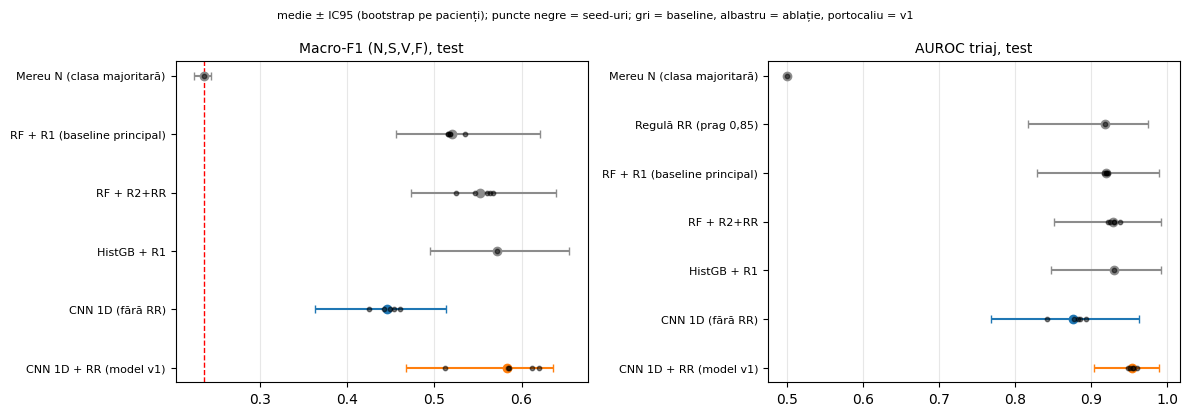

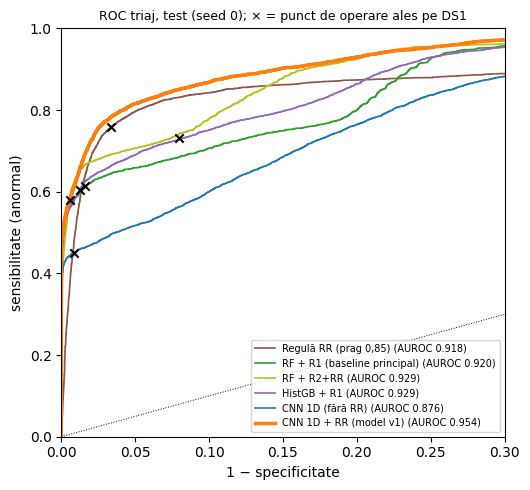

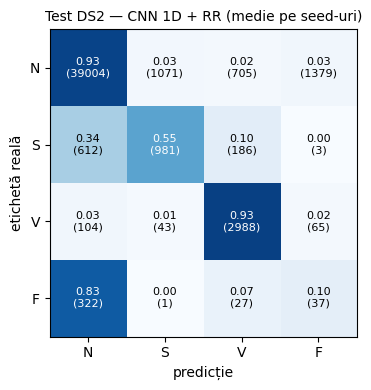

In [36]:
order4 = [k for k in ORDER if EVAL[k]['point']['macroF1'].size and not np.all(np.isnan(EVAL[k]['point']['macroF1']))]
colr = {'baseline': '0.55', 'ablatie': 'tab:blue', 'v1': 'tab:orange'}
LINE_COL = {'rule': 'tab:brown', 'rf_r1': 'tab:green', 'rf_r2rr': 'tab:olive', 'hgb_r1': 'tab:purple', 'cnn': 'tab:blue', 'cnn_rr': 'tab:orange'}
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, met, title in ((axs[0], 'macroF1', 'Macro-F1 (N,S,V,F), test'), (axs[1], 'AUROC', 'AUROC triaj, test')):
    ks = order4 if met == 'macroF1' else ORDER
    ys = np.arange(len(ks))[::-1]
    for y_, k in zip(ys, ks):
        v = np.nanmean(EVAL[k]['point'][met]); lo, hi = ci(EVAL[k]['boot'][met])
        ax.errorbar(v, y_, xerr=[[v - lo], [hi - v]], fmt='o', color=colr[METHODS[k]['role']], capsize=3)
        ax.scatter(EVAL[k]['point'][met], np.full(EVAL[k]['n_seeds'], y_), s=10, color='k', alpha=.5, zorder=3)
    ax.set_yticks(ys, [METHODS[k]['label'] for k in ks], fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.grid(axis='x', alpha=.3)
axs[0].axvline(EVAL['maj']['point']['macroF1'][0], color='r', ls='--', lw=1)
fig.suptitle('medie ± IC95 (bootstrap pe pacienți); puncte negre = seed-uri; gri = baseline, albastru = ablație, portocaliu = v1', fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT3}/fig_v1_principal_{COD}.png", dpi=150); plt.show()

# ROC de triaj (seed 0), cu punctele de operare
fig, ax = plt.subplots(figsize=(5.4, 5))
for k in ORDER:
    if k == 'maj':
        continue
    sc = method_scores(METHODS[k])[1][0]
    fpr, tpr, _ = roc_curve(abn_te, sc)
    ax.plot(fpr, tpr, label=f"{METHODS[k]['label']} (AUROC {np.mean(EVAL[k]['point']['AUROC']):.3f})", color=LINE_COL[k], lw=2.5 if k == 'cnn_rr' else 1.2)
    ax.scatter(1 - np.mean(EVAL[k]['point']['triSp']), np.mean(EVAL[k]['point']['triSe']), marker='x', color='k', zorder=4)
ax.plot([0, 1], [0, 1], 'k:', lw=.7)
ax.set_xlim(0, .3); ax.set_ylim(0, 1)
ax.set_xlabel('1 − specificitate'); ax.set_ylabel('sensibilitate (anormal)')
ax.set_title('ROC triaj, test (seed 0); × = punct de operare ales pe DS1', fontsize=9)
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.savefig(f"{OUT3}/fig_v1_roc_triaj_{COD}.png", dpi=150); plt.show()

# matrice de confuzie v1 (seed-uri mediate)
cmv = EVAL['cnn_rr']['cm_rec'].sum(0)
cmn = cmv / cmv.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cmn[i, j]:.2f}\n({cmv[i, j]:.0f})", ha='center', va='center', fontsize=8, color='w' if cmn[i, j] > .5 else 'k')
ax.set_xticks(range(K), CLASSES); ax.set_yticks(range(K), CLASSES)
ax.set_xlabel('predicție'); ax.set_ylabel('etichetă reală'); ax.set_title('Test DS2 — CNN 1D + RR (medie pe seed-uri)', fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT3}/fig_v1_confuzie_{COD}.png", dpi=150); plt.show()

In [37]:
summary = {'config': dict(EPOCHS=EPOCHS, LR_MAX=LR_MAX, BATCH=BATCH, seeds=SEEDS, SP_TARGET=SP_TARGET, N_BOOT=N_BOOT, device=DEVICE),
           'rezultate': res_df.round(4).to_dict(orient='records')}
with open(f"{OUT3}/summary_v1_{COD}.json", "w") as fh:
    json.dump(summary, fh, indent=1, ensure_ascii=False, default=float)
if os.path.isdir('/content/drive/MyDrive'):
    dst = '/content/drive/MyDrive/IC3_CP3_outputs'
    shutil.copytree(OUT3, dst, dirs_exist_ok=True)
    print("Copiat in Drive:", dst)
print("Fisiere:", sorted(os.listdir(OUT3)))

Copiat in Drive: /content/drive/MyDrive/IC3_CP3_outputs
Fisiere: ['fig_v1_confuzie_S5.png', 'fig_v1_principal_S5.png', 'fig_v1_roc_triaj_S5.png', 'per_inregistrare_S5.csv', 'results_v1_S5.csv', 'results_v1_S5_per_seed.csv', 'results_v1_S5_perechi.csv', 'summary_v1_S5.json', 'tabel_slide2_S5.csv']
